# 03 · Estimate and audit the hedge

Which past-only beta estimate reduces future market exposure without excessive instability?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

## Estimators and the decision clock

Every plotted estimate $\hat\beta_t$ uses data through t. The one-step diagnostic uses
$r^{BTC}_t-\hat\beta_{t-1}r^{QQQ}_t$; this evaluates a forecast, with idealized prior-close
execution. The additional-lag comparison uses $\hat\beta_{t-2}$ and matches the backtest's
information delay. Neither passive diagnostic includes costs or alpha-position sizing.

OLS and EWMA center returns, so they allow an intercept. The Kalman model estimates an intercept
and a random-walk beta with fixed process-noise settings; it updates observation variance from
past innovations. It is **filtered, never smoothed**. Posterior bands depend on those modeling
assumptions and do not capture all structural-break uncertainty. Beta clipping applies to trading
weights only; this scorecard evaluates the unbounded estimators fairly on common dates.

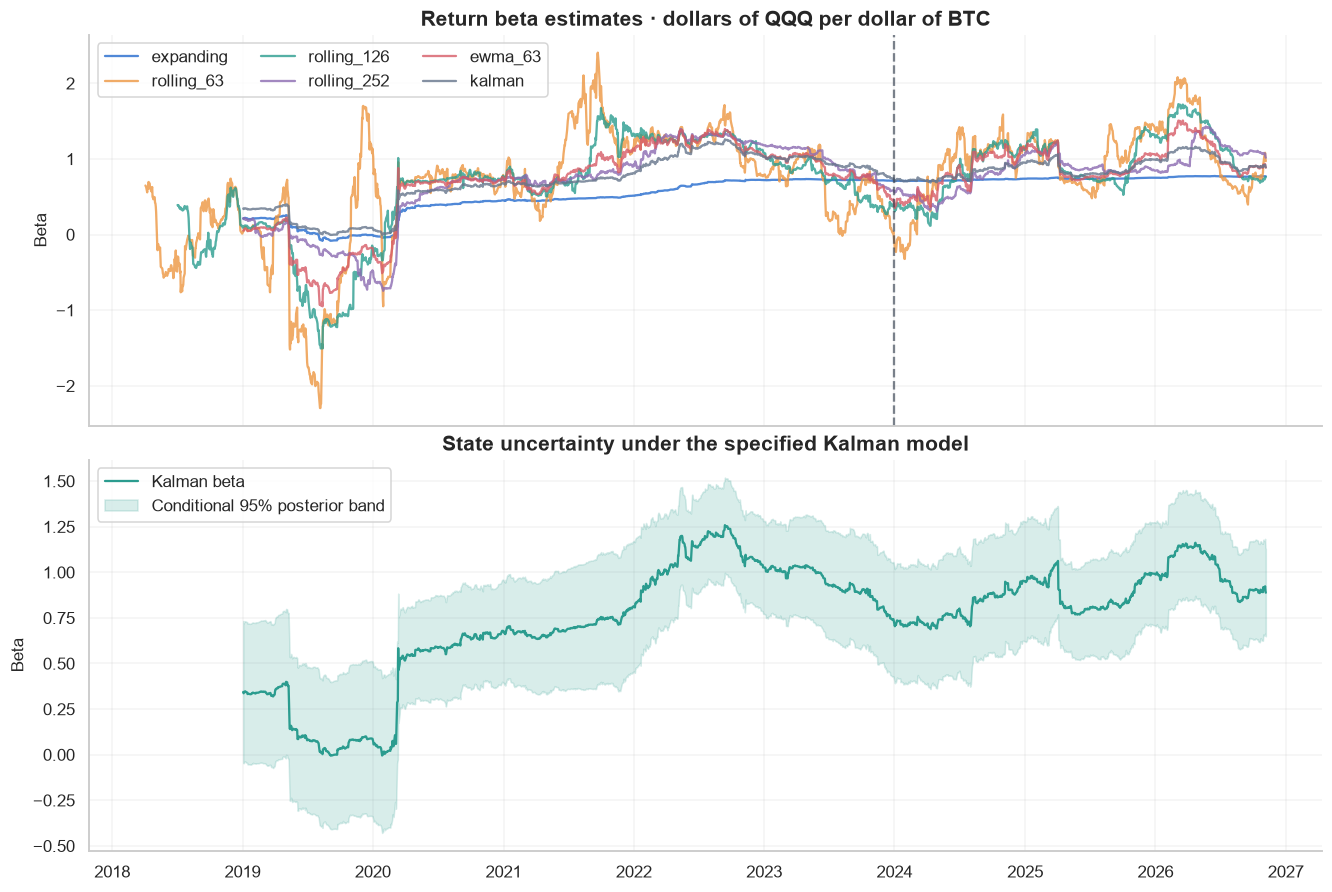

In [2]:
from btc_nasdaq.models import hedge_scorecard
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
betas.plot(ax=axes[0], alpha=.8)
axes[0].set(title="Return beta estimates · dollars of QQQ per dollar of BTC", ylabel="Beta")
axes[0].legend(ncol=3)
k = c["kalman"]
axes[1].plot(k.index, k.beta, color=PALETTE[2], label="Kalman beta")
axes[1].fill_between(k.index, k.beta-1.96*k.beta_se, k.beta+1.96*k.beta_se, color=PALETTE[2], alpha=.18, label="Conditional 95% posterior band")
axes[1].set(ylabel="Beta", title="State uncertainty under the specified Kalman model")
axes[1].legend()
shade_holdout(axes[0], HOLDOUT)
save_figure(fig, ROOT, "03_dynamic_betas")
plt.show()

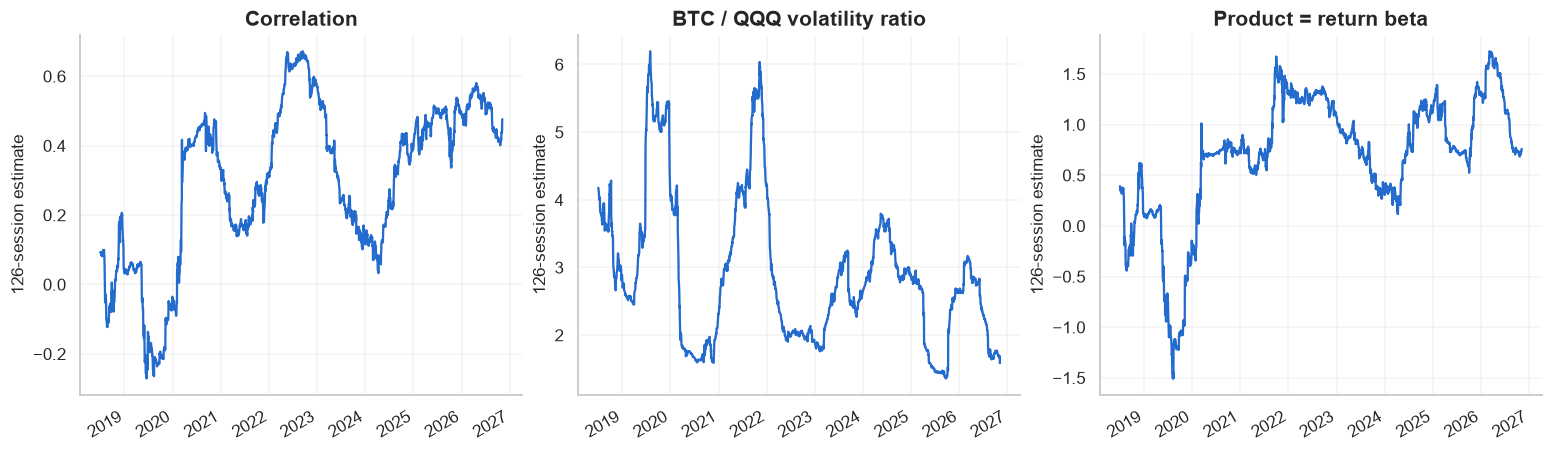

In [3]:
w = 126
rho = returns.btc.rolling(w).corr(returns.qqq)
vol_ratio = returns.btc.rolling(w).std() / returns.qqq.rolling(w).std()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, series, title in zip(axes, [rho, vol_ratio, rho*vol_ratio],
                            ["Correlation", "BTC / QQQ volatility ratio", "Product = return beta"]):
    series.plot(ax=ax)
    ax.set(title=title, xlabel="", ylabel="126-session estimate")
plt.show()

,n,annual_vol,variance_reduction,residual_beta,beta_ci_low,beta_ci_high,residual_corr,mean_beta_change,tail_5pct_mean
model,,,,,,,,,
unhedged,716,0.4830,0.0000,0.9423,0.7364,1.1482,0.4145,0.0000,-0.0618
expanding,716,0.4417,0.1636,0.1968,-0.0100,0.4037,0.0947,0.0005,-0.0553
rolling_63,716,0.4440,0.1550,-0.0655,-0.2641,0.1332,-0.0313,0.0396,-0.0559
rolling_126,716,0.4436,0.1562,-0.0702,-0.2851,0.1447,-0.0336,0.0194,-0.0566
rolling_252,716,0.4462,0.1464,-0.0214,-0.2645,0.2216,-0.0102,0.0100,-0.0569
ewma_63,716,0.4420,0.1625,-0.0205,-0.2367,0.1957,-0.0098,0.0151,-0.0560
kalman,716,0.4406,0.1678,0.0283,-0.1841,0.2407,0.0136,0.0060,-0.0553


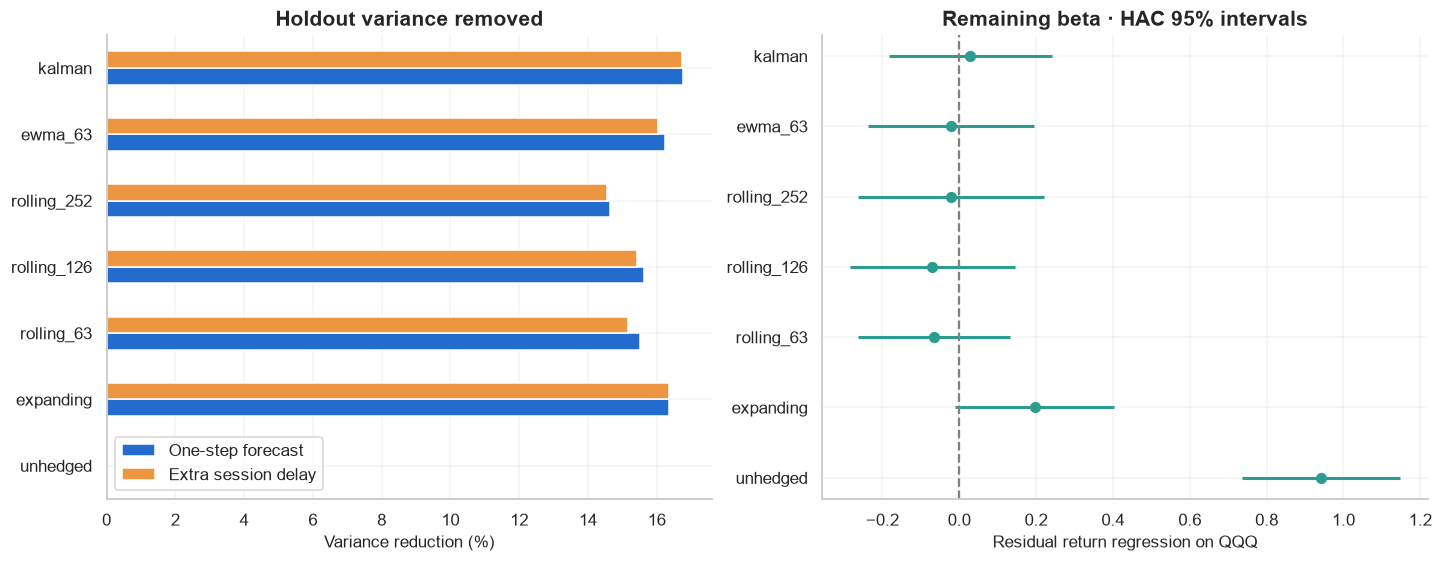

In [4]:
score = hedge_scorecard(returns, betas, start=HOLDOUT, lag=1)
delayed = hedge_scorecard(returns, betas, start=HOLDOUT, lag=2)
display(score)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pd.DataFrame({"One-step forecast": score.variance_reduction*100,
              "Extra session delay": delayed.variance_reduction*100}).plot.barh(ax=axes[0])
axes[0].set(title="Holdout variance removed", xlabel="Variance reduction (%)", ylabel="")
positions = np.arange(len(score))
axes[1].hlines(positions, score.beta_ci_low, score.beta_ci_high, color=PALETTE[2], lw=2)
axes[1].scatter(score.residual_beta, positions, color=PALETTE[2], s=40)
axes[1].axvline(0, color="gray", linestyle="--")
axes[1].set(yticks=positions, yticklabels=score.index, title="Remaining beta · HAC 95% intervals", xlabel="Residual return regression on QQQ")
save_figure(fig, ROOT, "03_hedge_scorecard")
plt.show()

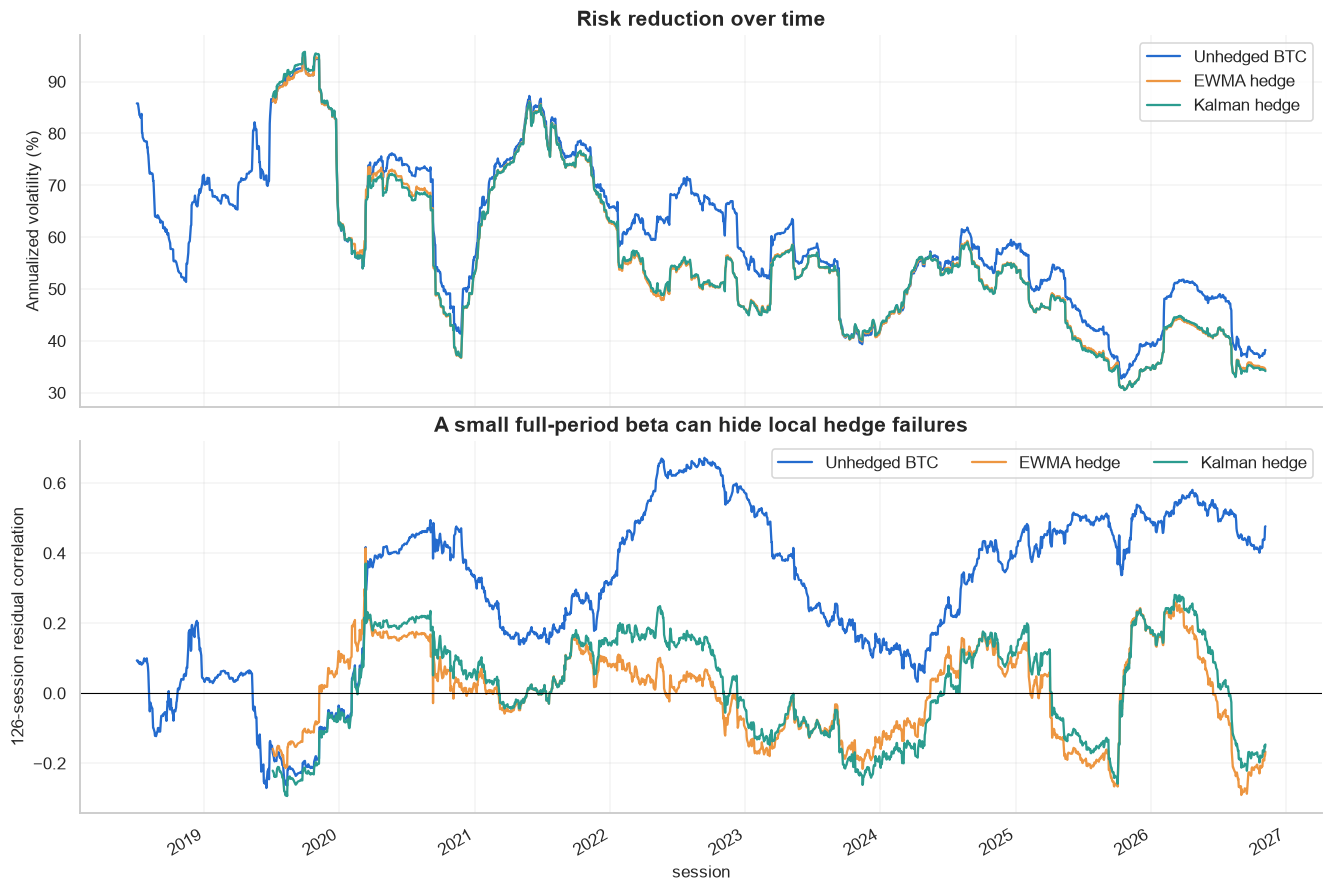

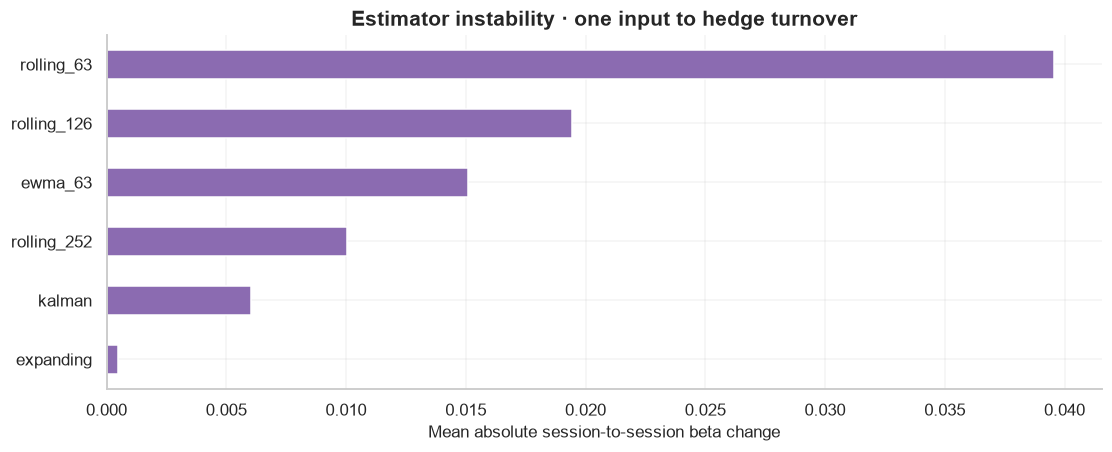

In [5]:
residuals = pd.DataFrame({"Unhedged BTC": returns.btc, "EWMA hedge": returns.btc-beta.shift(1)*returns.qqq,
                         "Kalman hedge": returns.btc-betas.kalman.shift(1)*returns.qqq})
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
residuals.rolling(126).std().mul(np.sqrt(252)*100).plot(ax=axes[0])
axes[0].set(title="Risk reduction over time", ylabel="Annualized volatility (%)")
for name in residuals:
    residuals[name].rolling(126).corr(returns.qqq).plot(ax=axes[1], label=name)
axes[1].axhline(0, color="black", lw=.7)
axes[1].set(title="A small full-period beta can hide local hedge failures", ylabel="126-session residual correlation")
axes[1].legend(ncol=3)
plt.show()
fig, ax = plt.subplots(figsize=(10, 4))
score.mean_beta_change.drop("unhedged").sort_values().plot.barh(ax=ax, color=PALETTE[3])
ax.set(title="Estimator instability · one input to hedge turnover", xlabel="Mean absolute session-to-session beta change", ylabel="")
plt.show()

**Read this before choosing a model:** residual correlation near zero is a useful exposure check,
not a guarantee of independence or lower tail losses. Compare variance, tail loss, rolling exposure,
uncertainty and turnover. EWMA-63 was the fixed first-pass baseline; inspecting this holdout
scorecard does not authorize selecting the best-looking model and reporting the same data as a new test.

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.